## MTL Trajet: 21 Pickup Dropoff Daily Chains (Flag 21)

### Dataset Overview

Complete daily histories for users with pick-up/drop-off activity, including ordered chain legs, activities, modes, follow-up gaps, destination areas, GPS positions, and point speeds.

The primary table is loaded into `df`; the supporting GPS table is loaded into `user_df`.

Goal: Analyze mobility patterns associated with pick-up and drop-off activities.

Role: Urban mobility-pattern analyst


Category: Complete daily histories for users with pick-up/drop-off activity, including ordered chain legs, activities, modes, follow-up gaps, destination areas, GPS positions, and point speeds.

Distances are calculated from delivered GPS polylines; average point speed and duration are synchronized with the point table. Montréal's long island axis runs approximately southwest–northeast, so signed axis displacement summarizes the dominant travel direction.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

## Load Dataset

The primary table is loaded into `df`; the supporting trajectory table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectories.csv"
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "trajectory_points.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: Are morning pick-up/drop-off trips short and motorized, and what follows them?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

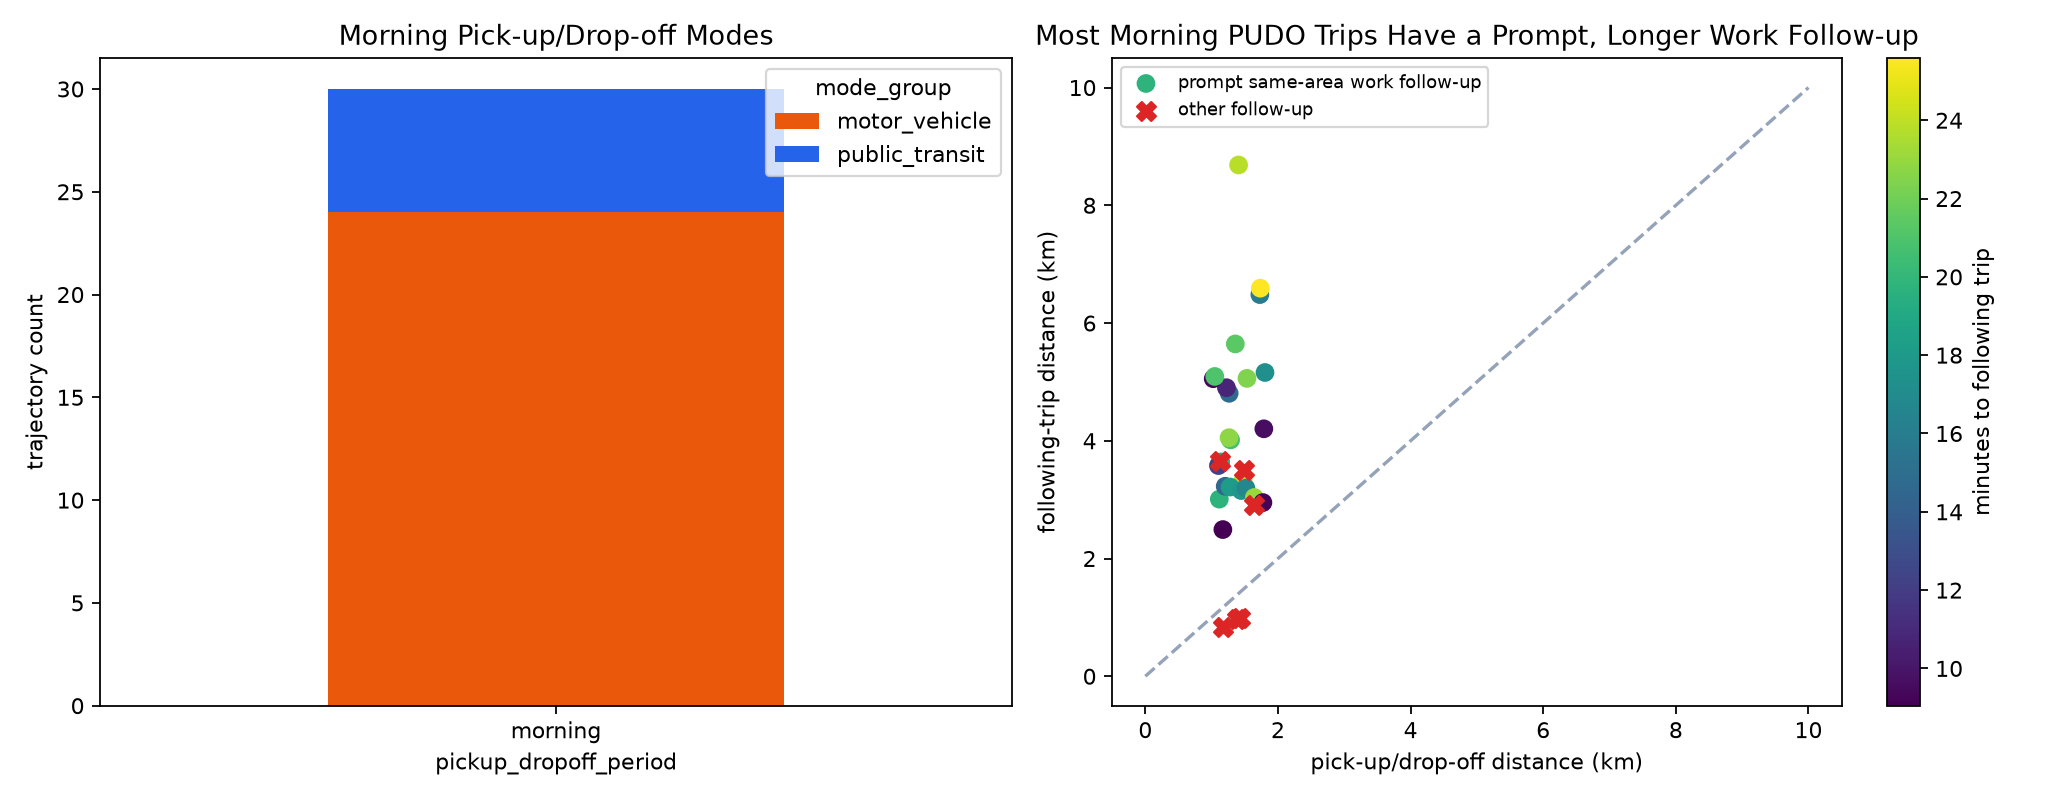

In [ ]:
df[df.pickup_dropoff_period.eq("morning")].groupby("mode_group").size()
df[df.pickup_dropoff_period.eq("morning")][
    ["distance_km", "next_departure_gap_minutes", "next_trip_purpose"]
]
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/morning_pudo_followup_work.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (6 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "morning_pudo_followup",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Morning Pick-up/Drop-off and Work Follow-up",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/morning_pudo_followup_work.png"
  },
  "question": "Are morning pick-up/drop-off trips short and motorized, and what follows them?",
  "code": "df[df.pickup_dropoff_period.eq('morning')].groupby('mode_group').size(); df[df.pickup_dropoff_period.eq('morning')][['distance_km','next_departure_gap_minutes','next_trip_purpose']]",
  "insight": "Morning pick-up/drop-off trips are mostly motorized, relatively short, and often followed by longer work trips departing soon from the same area.",
  "insight_type": "temporal_dynamics",
  "difficulty_level": 6,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trip_purpose",
    "trajectory_timestamp",
    "user_id",
    "trajectory_id",
    "transport_mode",
    "gps_position"
  ]
}

### **Question 2**: Where do afternoon pick-up/drop-off trips occur in daily chains and what follows them?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

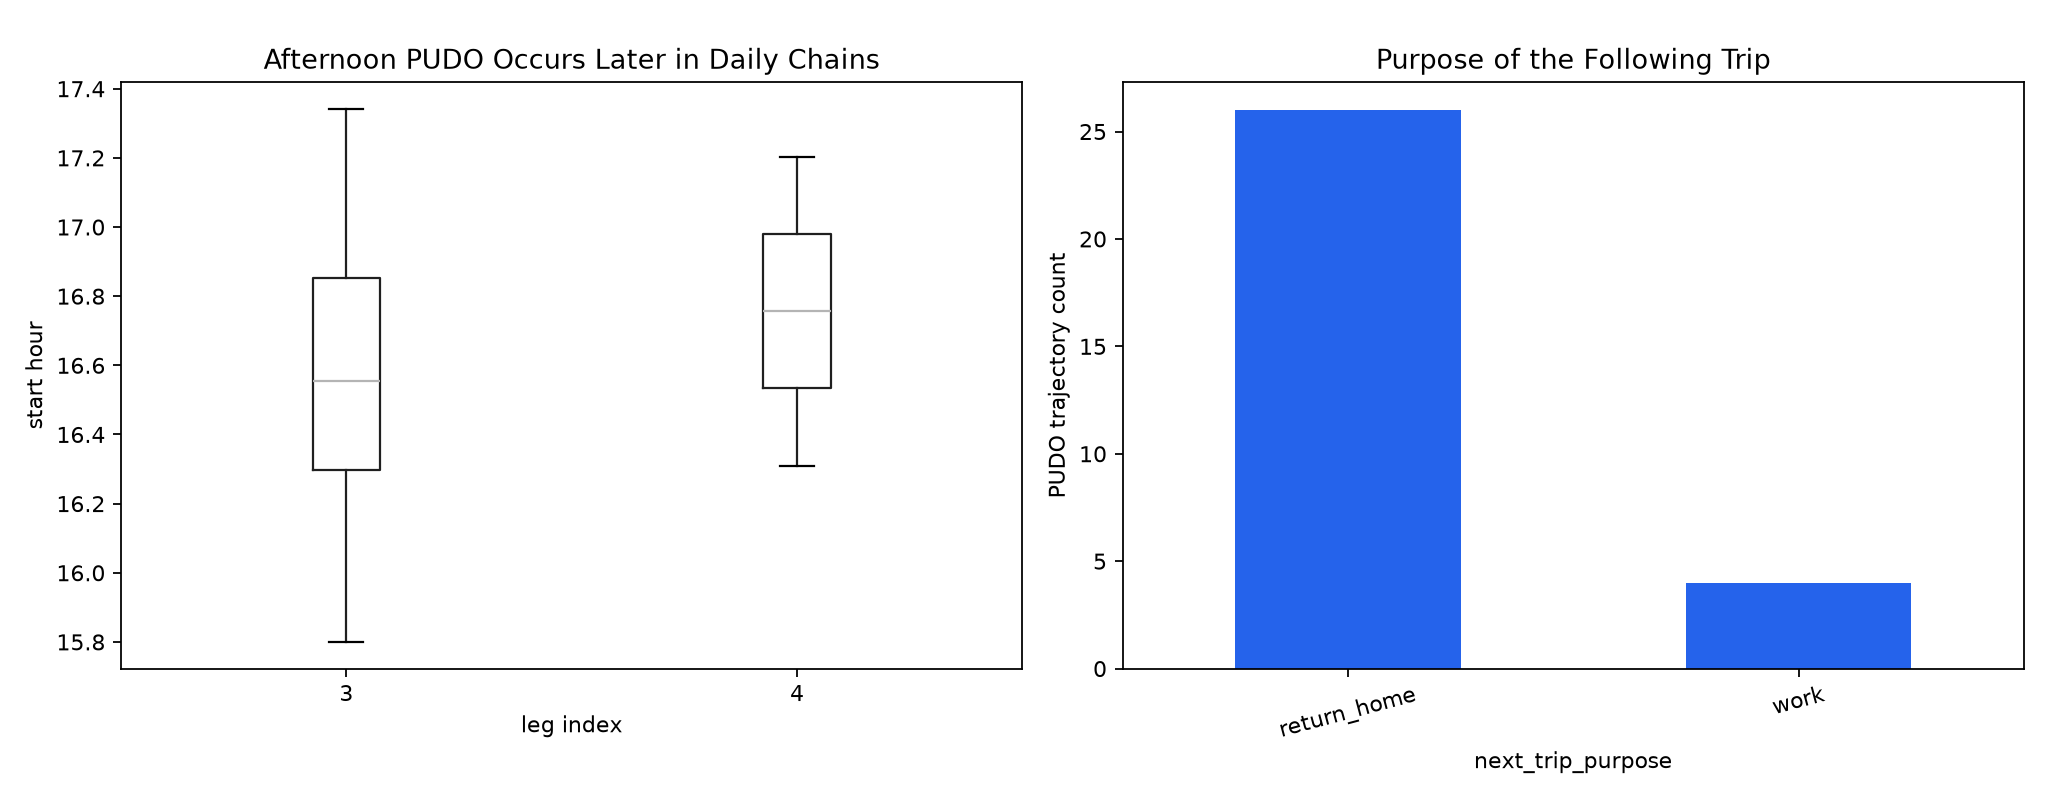

In [ ]:
df[df.pickup_dropoff_period.eq("afternoon")].groupby(
    ["leg_index", "next_trip_purpose"]
).size()
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/afternoon_pudo_chain_position.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "afternoon_pudo_followup",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Afternoon Pick-up/Drop-off Chain Position",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/afternoon_pudo_chain_position.png"
  },
  "question": "Where do afternoon pick-up/drop-off trips occur in daily chains and what follows them?",
  "code": "df[df.pickup_dropoff_period.eq('afternoon')].groupby(['leg_index','next_trip_purpose']).size()",
  "insight": "Afternoon pick-up/drop-off trips occur later in daily chains and are more often followed by return-home trips than additional work travel.",
  "insight_type": "temporal_dynamics",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trip_purpose",
    "trajectory_timestamp",
    "user_id",
    "trajectory_id"
  ]
}

### **Question 3**: Do repeated users retain similar pick-up/drop-off windows and areas while the rest of their day varies?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

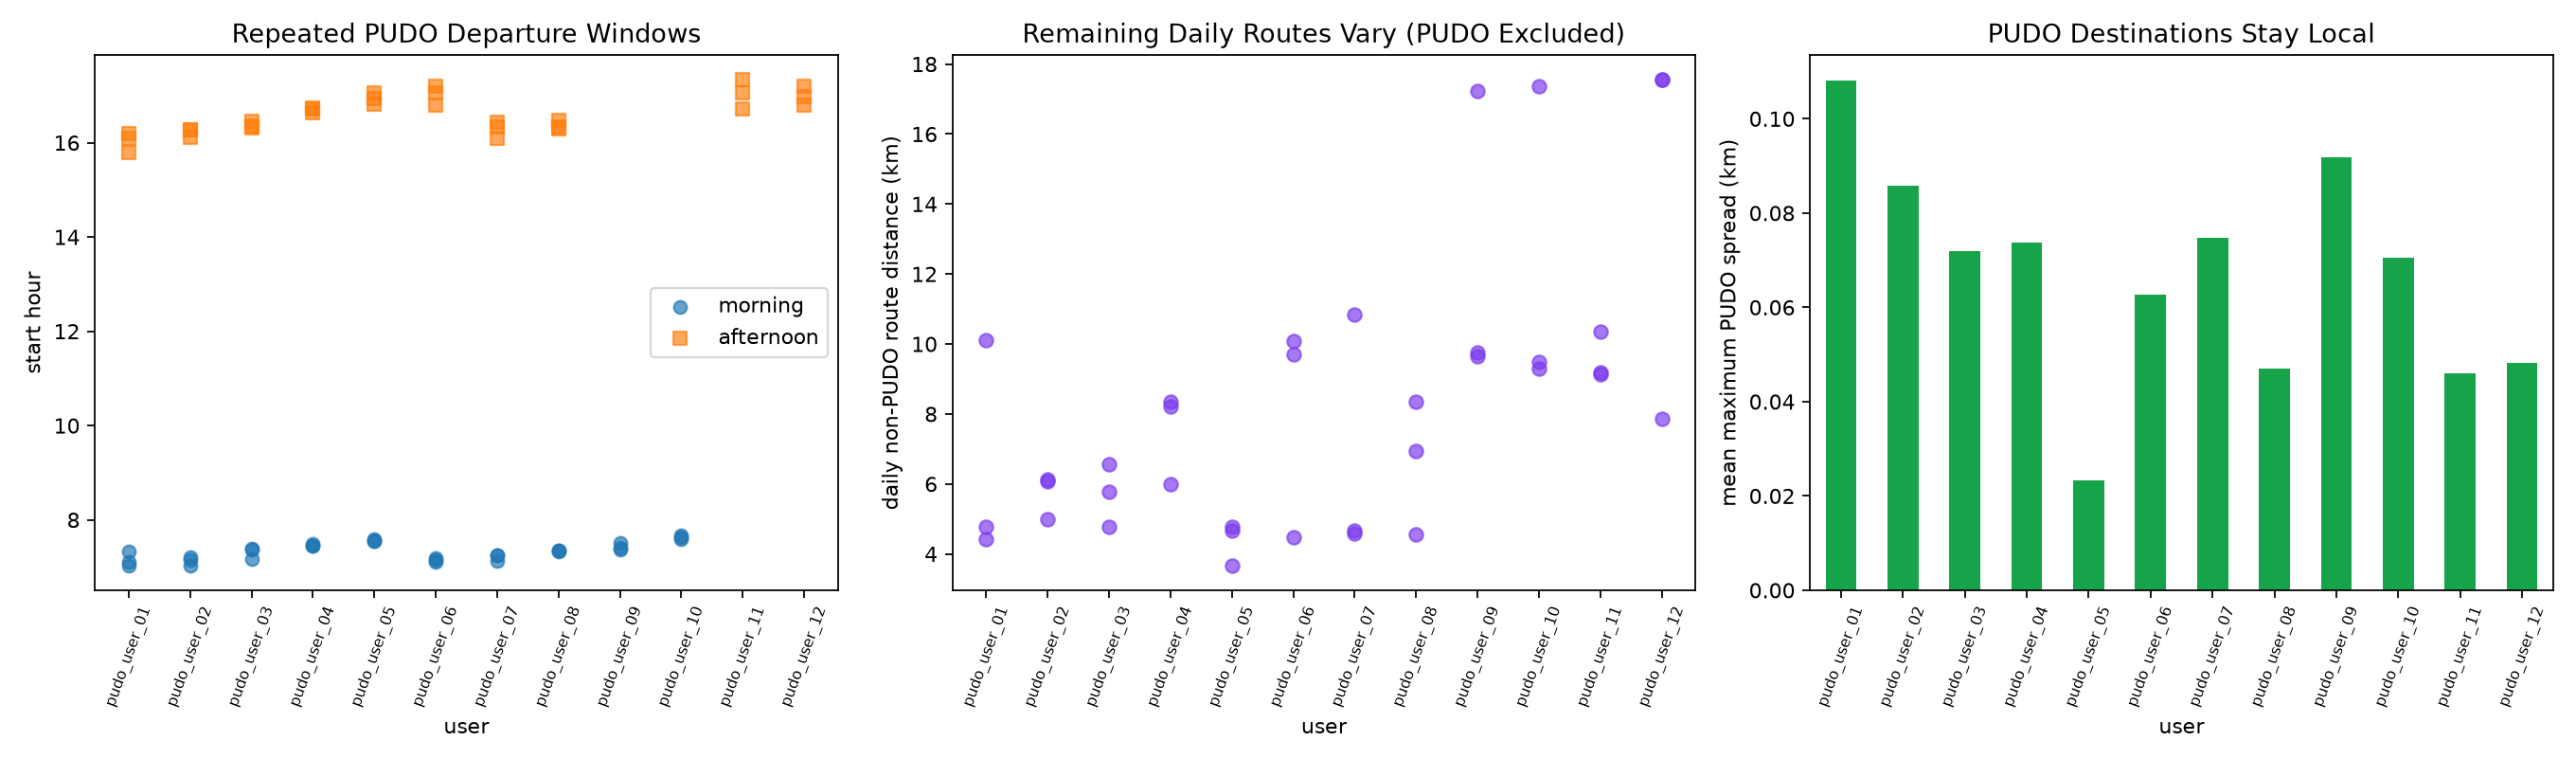

In [ ]:
df[df.is_pickup_dropoff].groupby(["user_id", "pickup_dropoff_period"])[
    ["start_hour", "user_period_destination_spread_km"]
].agg(["std", "max"])
df.groupby(["user_id", "chain_id"]).first().daily_non_pudo_distance_km
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/repeated_pudo_windows_daily_variation.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "repeated_pudo_daily_variation",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Repeated PUDO Windows and Daily Variation",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/repeated_pudo_windows_daily_variation.png"
  },
  "question": "Do repeated users retain similar pick-up/drop-off windows and areas while the rest of their day varies?",
  "code": "df[df.is_pickup_dropoff].groupby(['user_id','pickup_dropoff_period'])[['start_hour','user_period_destination_spread_km']].agg(['std','max']); df.groupby(['user_id','chain_id']).first().daily_non_pudo_distance_km",
  "insight": "Users with repeated pick-up/drop-off days keep similar departure windows and destination areas, while their remaining daily routes vary.",
  "insight_type": "overall_pattern",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "user_id",
    "trajectory_timestamp",
    "trajectory_id",
    "trip_purpose",
    "gps_position"
  ]
}

### **Question 4**: Which pick-up/drop-off trips use active modes without an immediate motorized follow-up?

#### Analysis action

Compare the relevant records and visual evidence before stating the observed pattern.

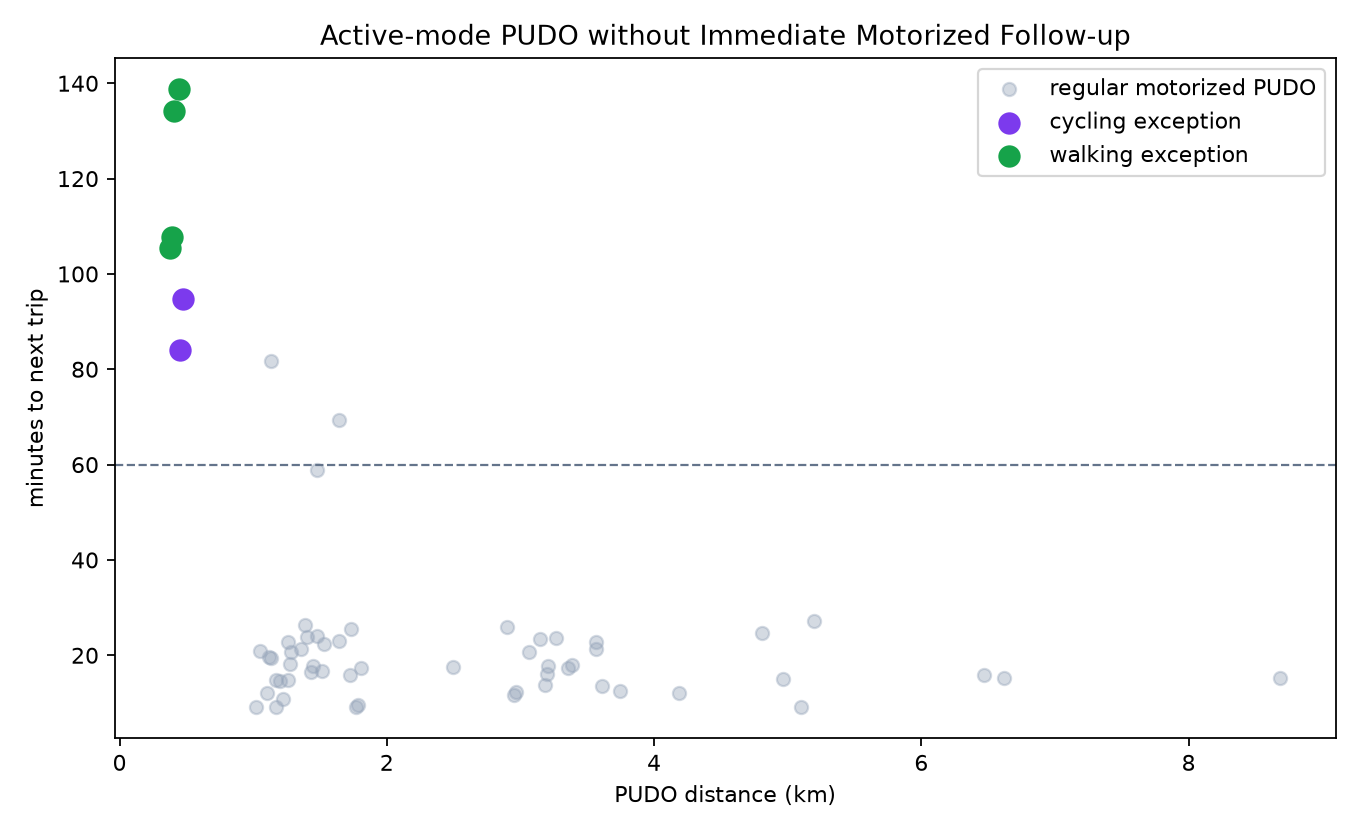

In [ ]:
df[df.is_active_exception][
    [
        "mode_group",
        "distance_km",
        "next_departure_gap_minutes",
        "immediate_motorized_followup",
    ]
]
plt.close("all")
# Display the verified visualization once.
display(Image(filename="visualizations/active_pudo_exceptions.png"))

#### Generate JSON Description for the Insight

**Insight difficulty: Very High (6 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "active_pudo_exception",
  "plot": {
    "plot_type": "trajectory_comparison",
    "title": "Active-mode Pick-up/Drop-off Exceptions",
    "description": "The plot is generated from the supplied case tables.",
    "file": "visualizations/active_pudo_exceptions.png"
  },
  "question": "Which pick-up/drop-off trips use active modes without an immediate motorized follow-up?",
  "code": "df[df.is_active_exception][['mode_group','distance_km','next_departure_gap_minutes','immediate_motorized_followup']]",
  "insight": "A few pick-up/drop-off trips use walking or cycling within mixed-use areas and are not followed by an immediate motorized trip.",
  "insight_type": "exception_deviation",
  "difficulty_level": 6,
  "difficulty_label": "very high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "trip_purpose",
    "trajectory_timestamp",
    "user_id",
    "trajectory_id",
    "transport_mode",
    "gps_position"
  ]
}

### Summary of Findings (Flag 21)

Morning pick-up/drop-off is short and predominantly motorized; most, but not all, are promptly followed from the same area by longer work travel. Afternoon pick-up/drop-off occurs later and usually precedes home; repeat users retain stable PUDO windows and areas despite variation elsewhere in the day, with six delayed active-mode exceptions.